**Disclaimer:** `Parts of this notebook might have been created with the assistance of large language models`                                 

## Imports and setup

In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
import warnings
import xgboost as xgb
warnings.filterwarnings('ignore')

np.random.seed(42)
sns.set_theme()

# Exploratory data analysis

We start by loading the entries from the given datasets.

In [80]:
train = pd.read_csv("data/track_k_ecommerce_returns_train.csv")
test = pd.read_csv("data/track_k_ecommerce_returns_test.csv")

Our dataset contains the following columns:

| Feature | Type | Range | Description |
|---|---|---|---|
| `price_eur` | float | 8–280 | Selling price in EUR. |
| `discount_pct` | float | 0–60 | Discount percentage. |
| `size_variants_count` | int | 1–12 | Number of available size variants. |
| `shipping_days` | float | 1–10 | Average shipping lead time. |
| `product_rating` | float | 2.2–5.0 | Product rating score. |
| `review_volume` | int | 5–600 | Number of reviews. |
| `image_quality_score` | float | 0–10 | Image quality score. |
| `description_quality_score` | float | 0–10 | Description quality score. |
| `size_mismatch_reports` | int | 0–35 | Historical mismatch report count. |
| `category_complexity_index` | float | 0–10 | Category complexity index. |
| `holiday_campaign_flag` | binary | 0/1 | Whether campaign runs in holiday period. |
| `packaging_color_code` | int | 1–6 | Packaging color category code. |
| **`return_rate_pct`** | float | 0–90 | **Target: expected return percentage.** |

We want to estimate `return_rate_pct` based on the 12 features. 

Here are quick numerical summaries of the features and target, we will try to explain the main trends thorugh visualization.

In [81]:
train.describe()

,price_eur,discount_pct,size_variants_count,shipping_days,product_rating,review_volume,image_quality_score,description_quality_score,size_mismatch_reports,category_complexity_index,holiday_campaign_flag,packaging_color_code,return_rate_pct
count,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000
mean,143.250631,29.976554,6.476154,5.319808,3.586992,140.546154,4.897954,5.977446,3.563077,4.964677,0.223077,3.468462,33.451762
std,78.916425,17.391667,3.400433,2.553168,0.800625,12.210378,2.845962,2.470796,1.854157,2.825049,0.416470,1.697189,23.006167
min,8.140000,0.030000,1.000000,1.010000,2.200000,102.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.200000
25%,73.622500,14.795000,4.000000,3.120000,2.900000,132.000000,2.370000,3.847500,2.000000,2.640000,0.000000,2.000000,13.590000
50%,141.545000,29.985000,6.500000,5.220000,3.600000,140.000000,4.890000,6.060000,3.000000,4.900000,0.000000,3.000000,25.195000
75%,213.002500,45.187500,9.000000,7.520000,4.252500,148.000000,7.260000,7.970000,5.000000,7.470000,0.000000,5.000000,57.625000
max,279.840000,59.990000,12.000000,10.000000,5.000000,184.000000,10.000000,10.000000,11.000000,9.990000,1.000000,6.000000,85.490000


## Heatmap

Before analyzing the distributions, it is useful to get initial insight into the data by plotting a heatmap of the correlation matrix:

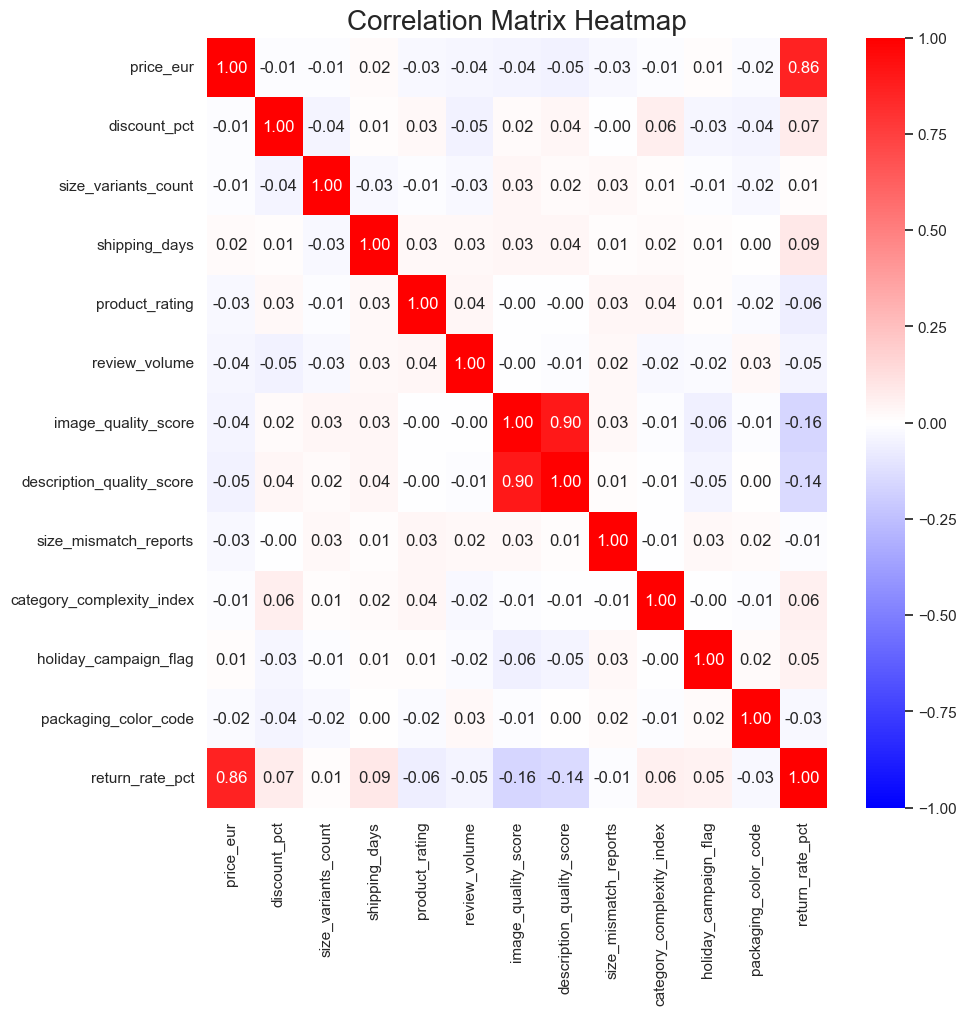

In [82]:
fig = plt.figure(figsize=(10,10))
plt.title("Correlation Matrix Heatmap", fontsize=20)
sns.heatmap(train.corr(), cmap="bwr", vmin ='-1', annot=True, fmt=".2f")
plt.show()

After an initial inspection of the heatmap, we can already observe:
- `price_eur` is **highly positively correlated** (0.86) with our target, which is `return_rate_pct` (more expensive products seem to be more likely to be returned)
- `image_quality_score` and `description_quality_score` are **negatively correlated** (-0.16, -0.14) with our target (products with lower quality presentation are more likely to be returned); at the same time, they are **highly positively correlated** with each other (0.9)
- excluding `image_quality_score` and `description_quality_score`, there doesn't seem to exist strong multicollinearity between the features themselves
- `discount_pct`, `shopping_days`, `cateogry_complexity_index`, `holiday_campaign_flag`, `review_volume`, `product_raiting` are not very highly correlated ($0.05 < |\cdot| < 0.09$) with the target, but as their names suggest, could still be reasonably relevant for the prediction (for example, we expect product raitings to somewhat affect the return rate)
- `size_variants_count`, `size_mismatch_reports` and `packaging_color_code` only show little correlation with the target 


## Distributions of features and target

## Target distribution is bimodal

First, it is important to analyze the distribution of the target (`return_rate_pct`):

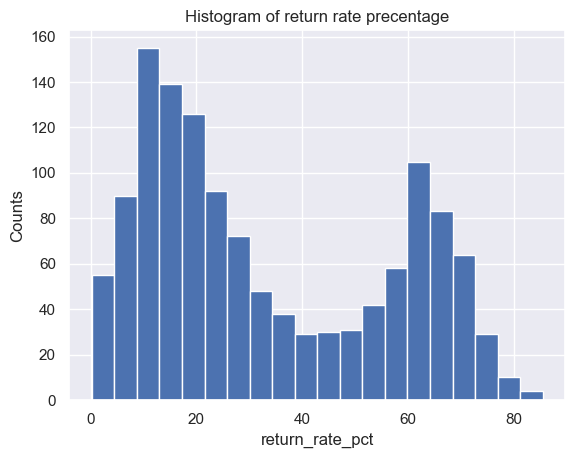

In [83]:
fig = plt.figure()
plt.title("Histogram of return rate precentage")
plt.ylabel("Counts")
plt.xlabel("return_rate_pct")
plt.hist(train['return_rate_pct'], bins=20)
plt.show()

It is a bimodal distribution with one peak around the 10-15% return rate and another around the 60-65% return rate. 

Our dataset doesn't seem to include a lot of entries in the middleground, so most campaigns either have a reasonbly low return rate, or a reasonbly high return rate, and the respective rates are approximately "normally distributed" with respect to the peaks.

This particular shape could be problematic in obtaining accurate predictions, so we will need to mitigate this issue when we start applying models.

## The bimodal distribution of the target reflected in relation to the features

When attempting to plot the features (except for `price_eur`) against `return_rate_pct` we observe a similar bimodal pattern.

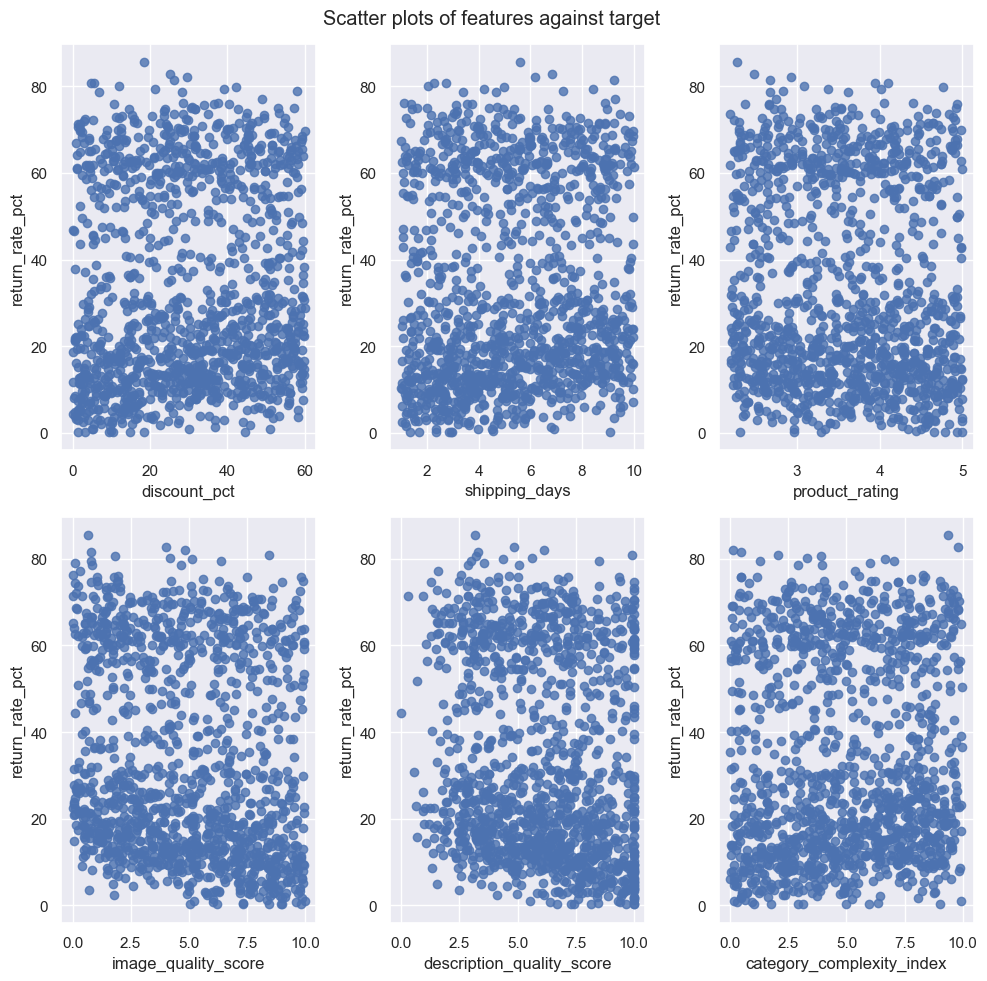

In [84]:
fig, axes = plt.subplots(2, 3, figsize=(10,10))
plt.suptitle("Scatter plots of features against target")

# Plot each of the selected features against the target
features = ['discount_pct', 'shipping_days', 'product_rating', 'image_quality_score', 'description_quality_score', 'category_complexity_index']
for i, ax in enumerate(axes.flat):
    ax.scatter(train[features[i]], train['return_rate_pct'], alpha=0.8)
    ax.set_xlabel(features[i])
    ax.set_ylabel('return_rate_pct')

plt.tight_layout()
plt.show()

- The middle region in each feature vs target scatterplot is caused by the existence of the two modes of the distribution of `return_rate_pct`. 
- Beyond this, the relationships between those features and the target are not perfectly clear; this is expected given the low correlation coefficients between most of the featuers and target. 

## Uniform distribution of fetures

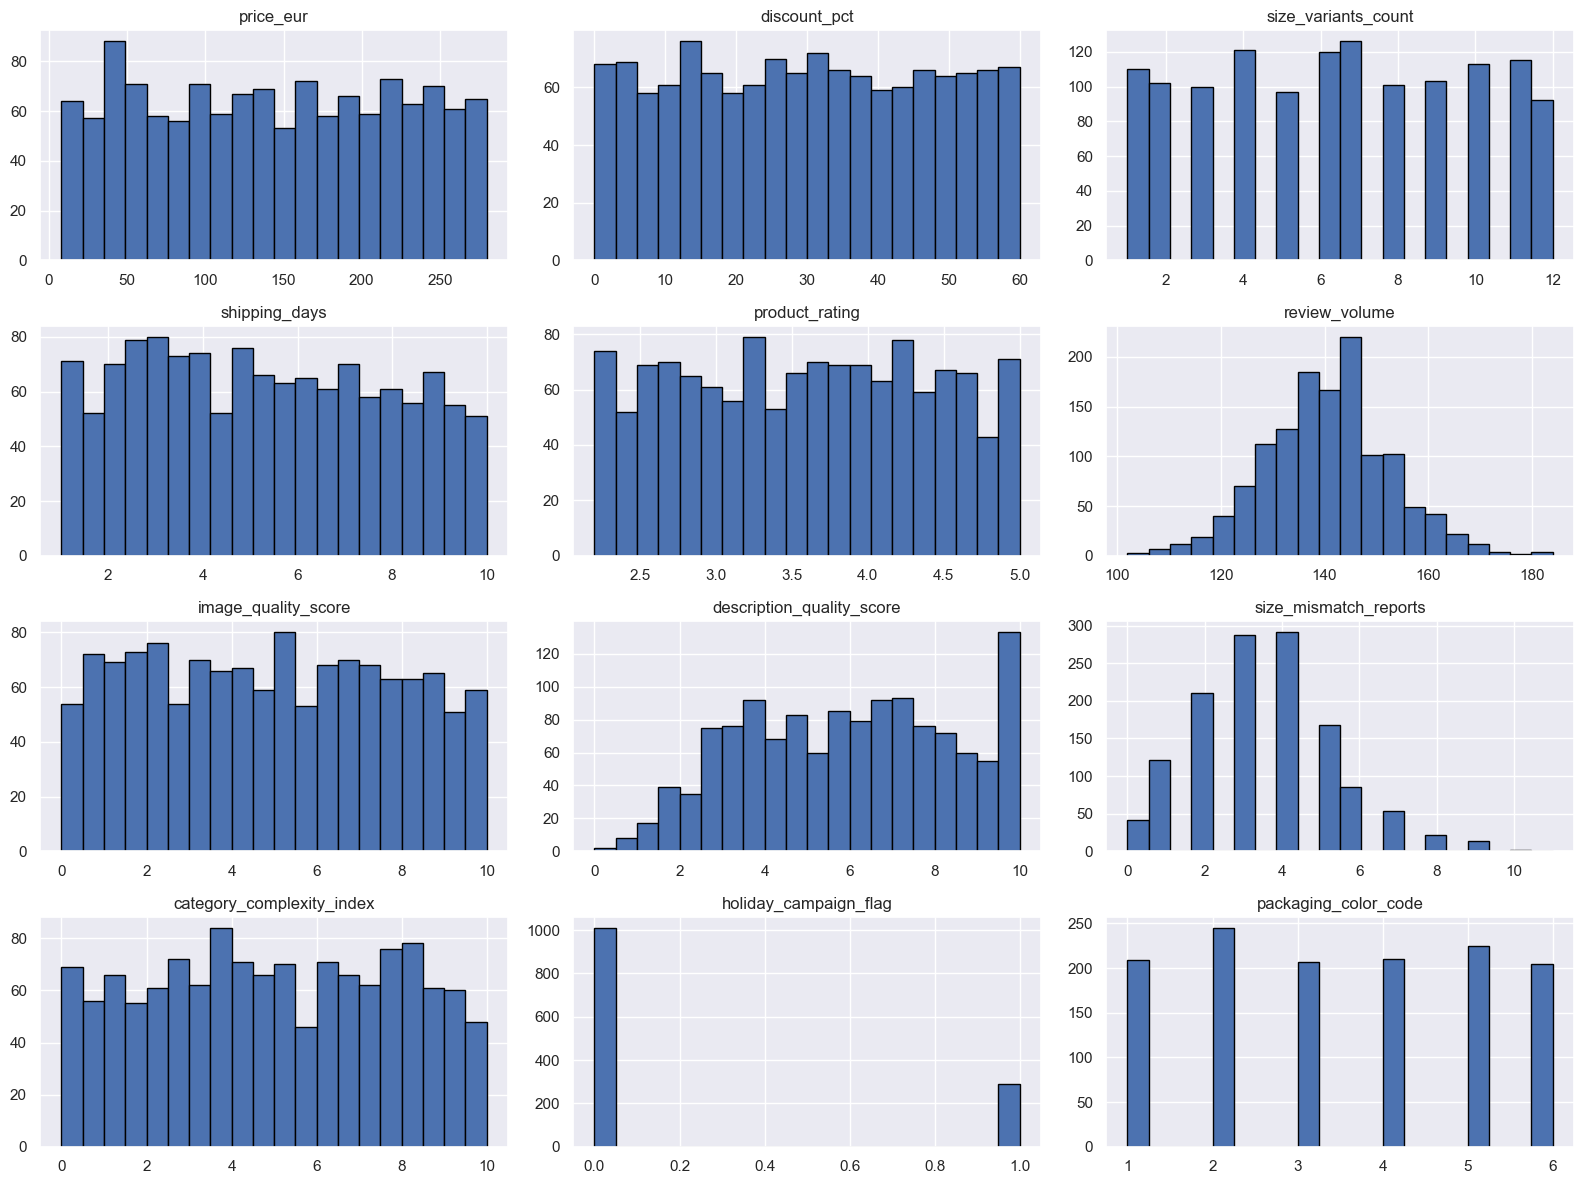

In [85]:
train.drop(columns=['return_rate_pct']).hist(figsize=(16, 12), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

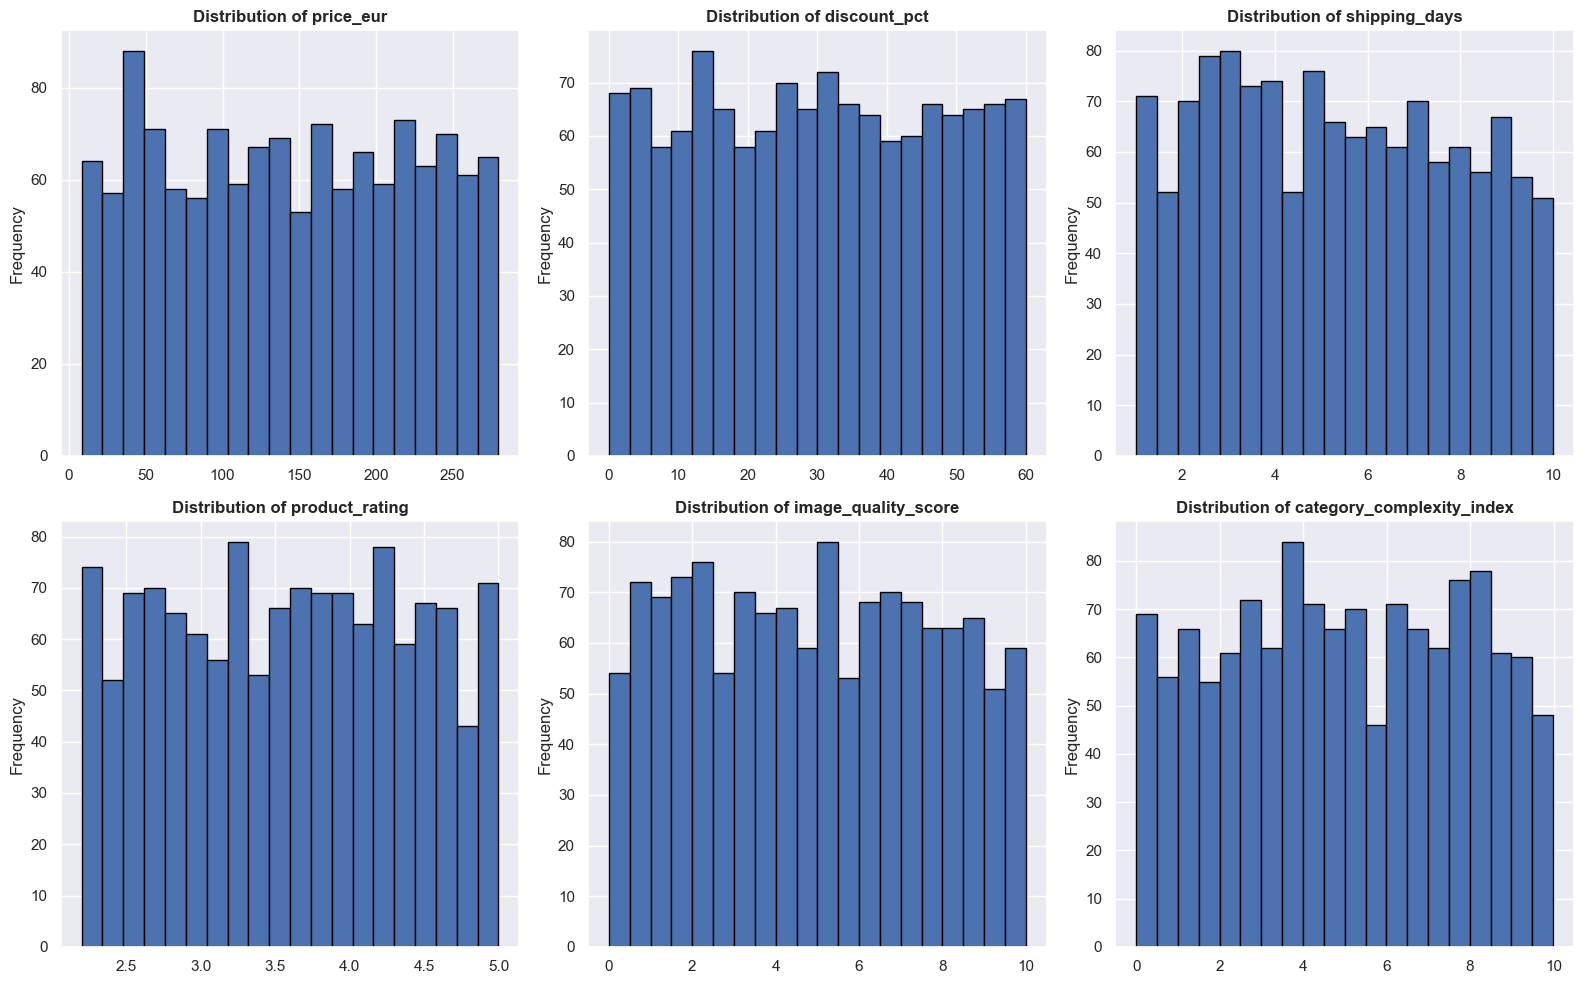

In [86]:
uniform_cols = [
    'price_eur', 
    'discount_pct', 
    'shipping_days', 
    'product_rating',
    'image_quality_score', 
    'category_complexity_index'
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(uniform_cols):
    axes[i].hist(train[col], bins=20, edgecolor='black')
    
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Most of the continuous data seems perfectly uniformely distributed. <br>
Nothing interesting seems to happen here.

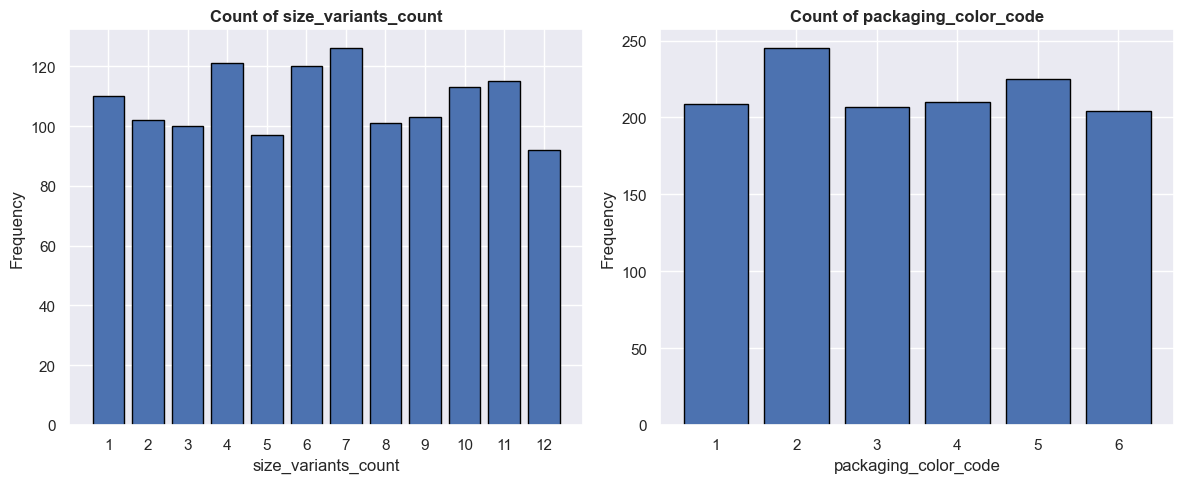

In [87]:
discrete_uniform_cols = [
    'size_variants_count', 
    'packaging_color_code'
]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

for i, col in enumerate(discrete_uniform_cols):
    counts = train[col].value_counts().sort_index()
    

    axes[i].bar(counts.index, counts.values, edgecolor='black')
    
    axes[i].set_title(f'Count of {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Frequency')
    axes[i].set_xlabel(col)
    
    axes[i].set_xticks(counts.index)

plt.tight_layout()
plt.show()

Two of the discrete features are uniform as well.<br>
Once again, nothing interesting happens here. 

We have 8 out of 12 features that are uniformly distributed. 

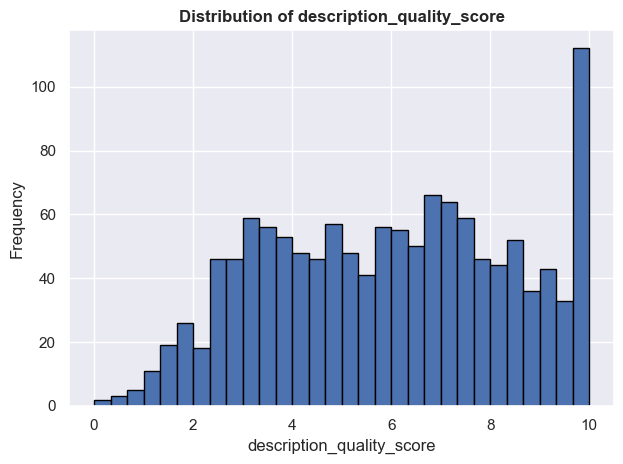

In [88]:
plt.hist(train['description_quality_score'], bins=30, edgecolor='black')

plt.title('Distribution of description_quality_score', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('description_quality_score')

plt.tight_layout()
plt.show()

The distribution of the description quality score is divided in three parts. 
- We can notice that the left tail is kind of missing between 0 and 2; Very few items have bad/garbage description.
- In the middle, it seems more uniformly distributed.
- On the far right side, we can see a peak of frequency.

Since it is the description quality score, we can suppose that most people won't even buy the low quality ones, hence the missing left tail. The middle is uniformly distributed so there's no much to say, but we can assume that the peak on the far right means that people are inclined to buy the items with excellent quality score.

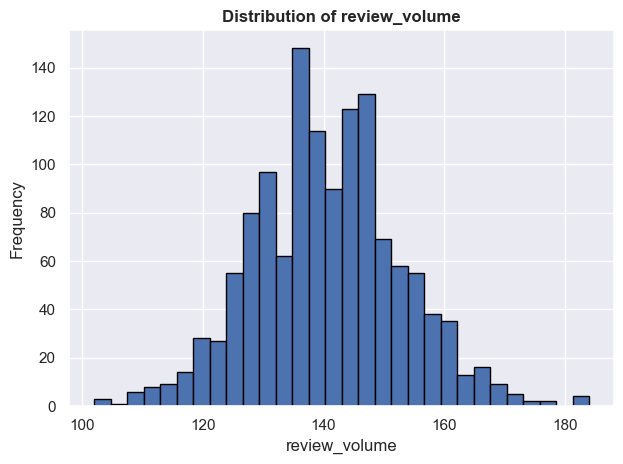

In [89]:
plt.hist(train['review_volume'], bins=30, edgecolor='black')

plt.title('Distribution of review_volume', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('review_volume')
plt.tight_layout()
plt.show()

The review volume seems perfectly normally distributed. Most of the items have around 140 review. It is also quite rare for the review to be too low or too high. 

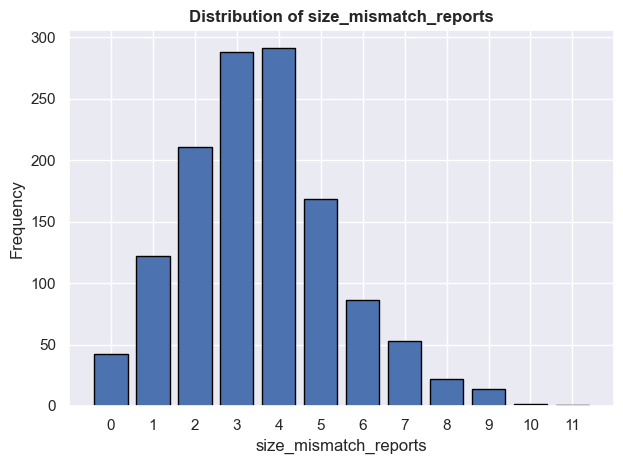

In [90]:
counts = train['size_mismatch_reports'].value_counts().sort_index()

plt.bar(counts.index, counts.values, edgecolor='black')

plt.title('Distribution of size_mismatch_reports', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('size_mismatch_reports')

plt.xticks(counts.index)

plt.tight_layout()
plt.show()

The distribution of size mismatch reports looks like a Poisson distribution. Since it is clearly right skewed, not looks like a normal, we can interpret it as a rare event. 

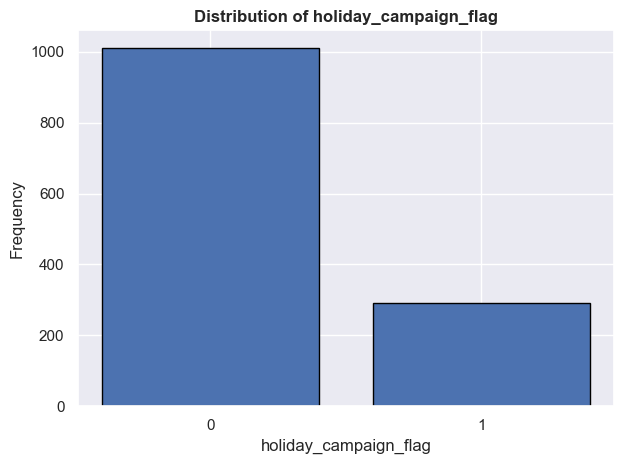

In [91]:
counts = train['holiday_campaign_flag'].value_counts().sort_index()

plt.bar(counts.index, counts.values, edgecolor='black')

plt.title('Distribution of holiday_campaign_flag', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('holiday_campaign_flag')

plt.xticks(counts.index)

plt.tight_layout()
plt.show()

## `price_eur` against the target 

Perhaps the most important predictor for our target is the `price_eur`, with a huge correlation coefficient of 0.86.

Let us vizualise their relationship:

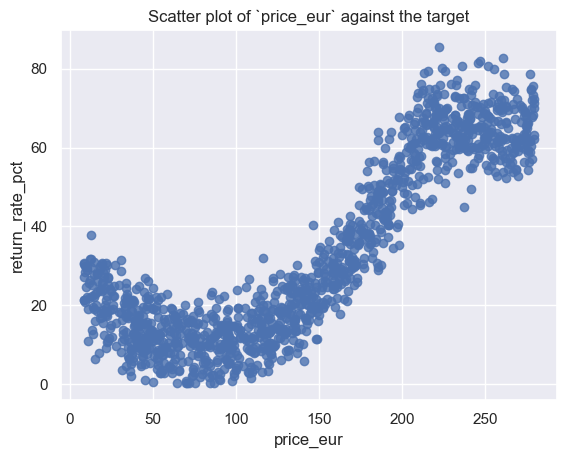

In [92]:
fig = plt.figure()
plt.title("Scatter plot of `price_eur` against the target")
plt.ylabel("return_rate_pct")
plt.xlabel("price_eur")
plt.scatter(train['price_eur'], train['return_rate_pct'], alpha=0.8)
plt.show()

The pattern resembles a polynomial of degree greater than 2 (we will look more into the exact degree later). This is promising for our model, as until this point, it is the clearest link between a feature and the target.

## The linear relationship between `image_quality_score` and `description_quality_score`

Pearson Correlation Coefficient: 0.90


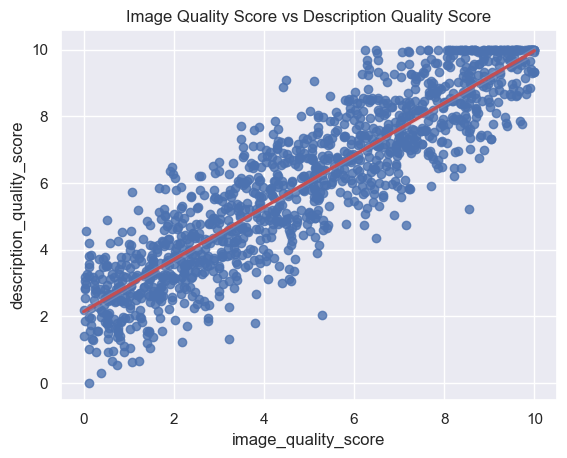

In [93]:
# Calculate the Pearson correlation coefficient
corr_coef = train['image_quality_score'].corr(train['description_quality_score'])
print(f"Pearson Correlation Coefficient: {corr_coef:.2f}")

# Plot the relationship
fig = plt.figure()
plt.title("Image Quality Score vs Description Quality Score")
sns.regplot(data=train, x='image_quality_score', y='description_quality_score', line_kws=dict(color="r"))
plt.show()

There is clearly a linear relationship between the `image_quality_score` and `description_quality_score` features, with a **Pearson Correlation Coefficient** of **0.90**.

# Models for making predictions

Before trying any model, let us establish a baseline using a model that simply predicts the mean.

In [94]:
def evaluate_model(model, X_train, y_train, X_test, y_test, return_model=False):
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    print(f"Train MSE: {mean_squared_error(y_train, y_pred_train):.4f}")
    print(f"Test MSE:  {mean_squared_error(y_test, y_pred_test):.4f}")

    if return_model:
        return y_pred_train, y_pred_test, model
    
    return y_pred_train, y_pred_test


class BaselineMeanModel:
    def __init__(self):
        self.mean_ = None

    def fit(self, X, Y):
        self.mean_ = np.mean(Y)
    
    def predict(self, X):
        return np.full(shape=(X.shape[0],), fill_value=self.mean_)
    

In [ ]:
# Here we are going to compare Ridge, Lasso and ElasticNet, each with its own set of hyperparameters. 
# We will use nested cross-validation to do that, which allows us to get an unbiased estimate of the test performance of the best model.

outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_ridge = {"alpha": np.logspace(-2, 4, 20)}
param_lasso = {"alpha": np.logspace(-4, 1, 20)}
param_elasticnet = {"alpha": np.logspace(-4, 1, 20), "l1_ratio": np.linspace(0, 1, 20)}
param_randomforest = {"n_estimators": [50, 100], "max_depth": [None, 5, 10]}

models = {
    'ridge': Ridge(),
    'lasso': Lasso(),
    'elasticnet': ElasticNet(),
    'randomforest': RandomForestRegressor(random_state=42),
    'xgboost': XGBoost()
}

outer_scores = {name: [] for name in models.keys()}

X = train.drop(columns=['return_rate_pct'])
y = train['return_rate_pct']


for train_idx, test_idx in outer_cv.split(X):
    # Outer CV is used to make the main split
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Inner CV for tuning
    inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)
    grid_models = {
        'ridge': GridSearchCV(models['ridge'], param_ridge, cv=inner_cv),
        'lasso': GridSearchCV(models['lasso'], param_lasso, cv=inner_cv),
        'elasticnet': GridSearchCV(models['elasticnet'], param_elasticnet, cv=inner_cv),
        'randomforest': GridSearchCV(models['randomforest'], param_randomforest, cv=inner_cv),
        'xgboost': GridSearchCV(models['xgboost'], param_xgboost, cv=inner_cv)
    }

    # See how now the fitting of the model + the searching of best hyperparameters looks like only one model
    for name, clf in grid_models.items():
        clf.fit(X_train, y_train)
        best_model = clf.best_estimator_
        mse = mean_squared_error(y_test, best_model.predict(X_test))
        outer_scores[name].append(mse)

print("Unbiased nested CV MSE:", {name: np.mean(scores) for name, scores in outer_scores.items()})
print("Unbiased nested CV MSE standard deviation:", {name: np.std(scores) for name, scores in outer_scores.items()})

Unbiased nested CV MSE: {'ridge': np.float64(120.98660948634767), 'lasso': np.float64(121.06536229114575), 'elasticnet': np.float64(121.1844474866858), 'randomforest': np.float64(28.57123621889526)}
Unbiased nested CV MSE standard deviation: {'ridge': np.float64(6.194058322302308), 'lasso': np.float64(6.145108151419566), 'elasticnet': np.float64(6.120185373250273), 'randomforest': np.float64(1.7835820179999404)}
